## Download data

In [6]:
!wget -c -P homework_data https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv

--2026-10-12 16:23:21--  https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv
Resolving opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)... 2a06:98c1:3120::9, 2a06:98c1:3121::9, 188.114.96.9, ...
Connecting to opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)|2a06:98c1:3120::9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 65007 (63K) [application/octet-stream]
Saving to: ‘homework_data/stations-2023-09.csv’

stations-2023-09.cs 100%[===================>]  63.48K  --.-KB/s    in 0.04s   

2026-10-12 16:23:21 (1.73 MB/s) - ‘homework_data/stations-2023-09.csv’ saved [65007/65007]



In [7]:
!wget -c -P homework_data https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv

--2026-10-12 16:23:23--  https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv
Resolving opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)... 2a06:98c1:3120::9, 2a06:98c1:3121::9, 188.114.96.9, ...
Connecting to opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)|2a06:98c1:3120::9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 583534 (570K) [application/octet-stream]
Saving to: ‘homework_data/tariff-distances-2022-01.csv’

tariff-distances-20 100%[===================>] 569.86K  --.-KB/s    in 0.1s    

2026-10-12 16:23:23 (5.27 MB/s) - ‘homework_data/tariff-distances-2022-01.csv’ saved [583534/583534]



In [8]:
%%bash
for year in {2011..2023}; do
    wget -c -P homework_data "https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-${year}.csv"
done

--2026-10-12 16:23:25--  https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-2011.csv


Resolving opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)... 2a06:98c1:3120::9, 2a06:98c1:3121::9, 188.114.96.9, ...
Connecting to opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)|2a06:98c1:3120::9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 410085 (400K) [application/octet-stream]
Saving to: ‘homework_data/disruptions-2011.csv’

     0K .......... .......... .......... .......... .......... 12% 3.75M 0s
    50K .......... .......... .......... .......... .......... 24% 1.16M 0s
   100K .......... .......... .......... .......... .......... 37% 3.40M 0s
   150K .......... .......... .......... .......... .......... 49% 3.03M 0s
   200K .......... .......... .......... .......... .......... 62% 2.91M 0s
   250K .......... .......... .......... .......... .......... 74% 5.10M 0s
   300K .......... .......... .......... .......... .......... 87% 5.74M 0s
   350K .......... .......... .......... .......... .......... 99% 7.03M 0s
   400K    

In [9]:
%%bash
for year in {2019..2025}; do
    wget -c -P homework_data "https://opendata.rijdendetreinen.nl/public/services/services-${year}.csv.gz"
done

--2026-10-12 16:23:29--  https://opendata.rijdendetreinen.nl/public/services/services-2019.csv.gz
Resolving opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)... 2a06:98c1:3120::9, 2a06:98c1:3121::9, 188.114.96.9, ...
Connecting to opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)|2a06:98c1:3120::9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 382832398 (365M) [application/octet-stream]
Saving to: ‘homework_data/services-2019.csv.gz’

     0K .......... .......... .......... .......... ..........  0% 2.53M 2m24s
    50K .......... .......... .......... .......... ..........  0% 2.19M 2m35s
   100K .......... .......... .......... .......... ..........  0%  802K 4m19s
   150K .......... .......... .......... .......... ..........  0% 6.17M 3m29s
   200K .......... .......... .......... .......... ..........  0% 3.15M 3m10s
   250K .......... .......... .......... .......... ..........  0% 1.53M 3m18s
   300K .......... .......... .......... ...

## Put data to the db

In [18]:
import duckdb

db = duckdb.connect("homework_data/homework.duckdb")
db.sql("""
CREATE TABLE IF NOT EXISTS stations AS
SELECT *
FROM read_csv('homework_data/stations-2023-09.csv')
""")

## Create distances and distnaces_long

In [19]:
db.sql("""
CREATE TABLE IF NOT EXISTS distances AS
SELECT *
FROM read_csv(
    'homework_data/tariff-distances-2022-01.csv',
    nullstr = ['XXX', '?']
)
""")

In [20]:
db.sql("""
CREATE TABLE IF NOT EXISTS distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE Station)
INTO NAME other_station VALUE distance
""")

## Disruptions

#### Connected to Postgres

In [24]:
db.sql("INSTALL postgres")
db.sql("LOAD postgres")

db.sql("""
ATTACH IF NOT EXISTS
    'host=localhost user=postgres password=postgres dbname=postgres'
AS postgres_hw (TYPE postgres)
""")

In [26]:
files = [f"homework_data/disruptions-{year}.csv" for year in range(2011, 2024)]

db.read_csv(files, union_by_name=True).create_view(
    "homework_disruptions_csv",
    replace=True,
)

db.sql("""
CREATE TABLE IF NOT EXISTS postgres_hw.public.disruptions AS
SELECT *
FROM homework_disruptions_csv
""")

## Transform train services to parquet

In [30]:
files = [f"homework_data/services-{year}.csv.gz" for year in range(2019, 2026)]

db.execute(
    """
COPY (
    SELECT *
    FROM read_csv(?, union_by_name = true)
)
TO 'homework_data/services-2019-2025.parquet'
(FORMAT PARQUET, COMPRESSION ZSTD)
""",
    [files],
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [31]:
db.sql("""
CREATE TABLE IF NOT EXISTS services AS
SELECT *
FROM read_parquet('homework_data/services-2019-2025.parquet')
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## Queries for task 7

In [41]:
db.sql("SHOW ALL TABLES")

┌─────────────┬─────────┬──────────────────────────┬────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

### 1. How many trains departed from Amsterdam Central station overall?

In [40]:
db.sql("""
SELECT COUNT(*) AS departures
FROM services
WHERE "Stop:Station code" = 'ASD'
  AND "Stop:Departure time" IS NOT NULL
  AND NOT COALESCE("Stop:Departure cancelled", false)
""")

┌────────────┐
│ departures │
│   int64    │
├────────────┤
│    1799338 │
└────────────┘

### 2. Calculate the average arrival delay of different service types (Service:Type). Order results descending by average delay.

In [42]:
db.sql("""
SELECT
    "Service:Type" AS service_type,
    AVG(COALESCE("Stop:Arrival delay", 0)) AS avg_delay_minutes
FROM services
WHERE "Stop:Arrival time" IS NOT NULL
  AND NOT COALESCE("Stop:Arrival cancelled", false)
GROUP BY "Service:Type"
ORDER BY avg_delay_minutes DESC
""")

┌──────────────────────┬────────────────────┐
│     service_type     │ avg_delay_minutes  │
│       varchar        │       double       │
├──────────────────────┼────────────────────┤
│ Alpen Express        │ 27.826625386996906 │
│ Krokus Express       │ 18.304347826086957 │
│ European Sleeper     │ 14.586860947117197 │
│ Nightjet             │  9.899677832472886 │
│ ICE                  │  7.980199633326543 │
│ Eurostar             │  7.529096219326054 │
│ ICE International    │ 5.8218471729171215 │
│ Thalys               │  5.707678662849808 │
│ Int. Trein           │ 4.1849509269356595 │
│ Nachttrein           │  4.056489262371615 │
│     ·                │                 ·  │
│     ·                │                 ·  │
│     ·                │                 ·  │
│ Niet instappen       │                0.0 │
│ stoptrein            │                0.0 │
│ Snelbus i.p.v. trein │                0.0 │
│ Taxibus ipv trein    │                0.0 │
│ Belbus               │          

### 3. What was the most common disruption cause in different years? MODE function may be useful.

In [44]:
db.sql("""
SELECT
    EXTRACT(YEAR FROM start_time) AS year,
    MODE(statistical_cause_en ORDER BY statistical_cause_en) AS most_common_cause
FROM postgres_hw.public.disruptions
GROUP BY year
""")

┌───────┬───────────────────┐
│ year  │ most_common_cause │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2024 │ broken down train │
│  2023 │ broken down train │
└───────┴───────────────────┘

#### 4. How many trains started their overall service in any Amsterdam station?

In [46]:
db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS services_started_in_amsterdam
FROM services
WHERE "Stop:Station name" ILIKE 'Amsterdam%'
  AND "Stop:Arrival time" IS NULL
  AND "Stop:Departure time" IS NOT NULL
  AND NOT COALESCE("Service:Completely cancelled", false)
""")

┌───────────────────────────────┐
│ services_started_in_amsterdam │
│             int64             │
├───────────────────────────────┤
│                       1203209 │
└───────────────────────────────┘

#### 5. What fraction of services was run to final destinations outside the Netherlands?

In [ ]:
db.sql("""
WITH final_stops AS (
    SELECT DISTINCT
        "Service:RDT-ID" AS service_id,
        UPPER("Stop:Station code") AS station_code
    FROM services
    WHERE "Stop:Departure time" IS NULL
      AND NOT COALESCE("Service:Completely cancelled", false)
),
counts AS (
    SELECT
        COUNT(DISTINCT f.service_id) AS total_services,
        COUNT(DISTINCT f.service_id)
            FILTER (WHERE s.country <> 'NL') AS international_services,
        COUNT(DISTINCT f.service_id)
            FILTER (WHERE s.country IS NULL) AS unknown_destination_services
    FROM final_stops f
    LEFT JOIN stations s ON f.station_code = UPPER(s.code)
)
SELECT *,
    international_services * 1.0 / NULLIF(total_services, 0)
        AS international_fraction
FROM counts
""")

┌────────────────┬────────────────────────┬──────────────────────────────┬────────────────────────┐
│ total_services │ international_services │ unknown_destination_services │ international_fraction │
│     int64      │         int64          │            int64             │         double         │
├────────────────┼────────────────────────┼──────────────────────────────┼────────────────────────┤
│       15844305 │                 601350 │                        13988 │    0.03795370008340536 │
└────────────────┴────────────────────────┴──────────────────────────────┴────────────────────────┘

In [ ]:
db.sql("""
SELECT
    s1.name_long AS start_station,
    s2.name_long AS end_station,
    d.distance
FROM distances_long d
JOIN stations s1 ON UPPER(d.Station) = UPPER(s1.code)
JOIN stations s2 ON UPPER(d.other_station) = UPPER(s2.code)
WHERE s1.country = 'NL'
  AND s2.country = 'NL'
  AND d.Station < d.other_station
ORDER BY d.distance DESC, start_station, end_station
LIMIT 1
""")

┌───────────────┬─────────────┬──────────┐
│ start_station │ end_station │ distance │
│    varchar    │   varchar   │  int64   │
├───────────────┼─────────────┼──────────┤
│ Eemshaven     │ Vlissingen  │      426 │
└───────────────┴─────────────┴──────────┘

#### 7. Compare the average arrival delay between different train operators (Service:Company) on a bar plot. Sort them appropriately.

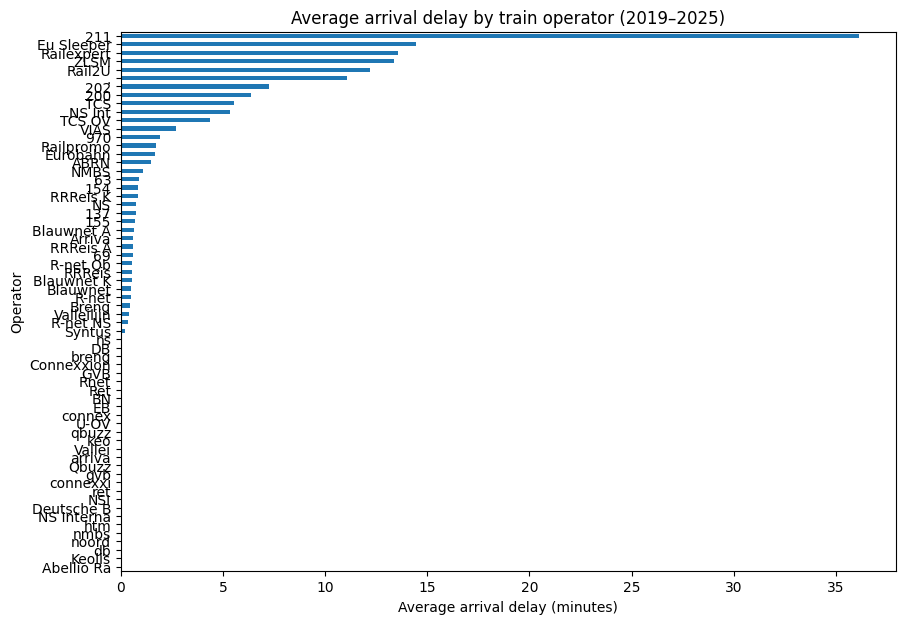

In [ ]:
import matplotlib.pyplot as plt

operator_delays = db.sql("""
SELECT
    "Service:Company" AS operator,
    AVG(COALESCE("Stop:Arrival delay", 0)) AS avg_delay_minutes
FROM services
WHERE "Stop:Arrival time" IS NOT NULL
  AND NOT COALESCE("Stop:Arrival cancelled", false)
GROUP BY "Service:Company"
ORDER BY avg_delay_minutes ASC
""").df()

ax = operator_delays.plot.barh(
    x="operator",
    y="avg_delay_minutes",
    figsize=(10, 7),
    legend=False,
    title="Average arrival delay by train operator (2019–2025)",
)
ax.set_xlabel("Average arrival delay (minutes)")
ax.set_ylabel("Operator")
plt.show()

#### 8. How many services were disrupted in different years? Make a line plot.

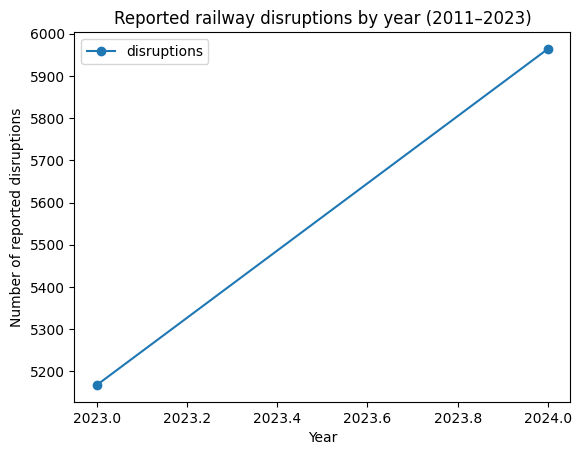

In [56]:
yearly_disruptions = db.sql("""
SELECT
    EXTRACT(YEAR FROM start_time) AS year,
    COUNT(DISTINCT rdt_id) AS disruptions
FROM postgres_hw.public.disruptions
GROUP BY year
ORDER BY year
""").df()

ax = yearly_disruptions.plot.line(
    x="year",
    y="disruptions",
    marker="o",
    title="Reported railway disruptions by year (2011–2023)",
)
ax.set_xlabel("Year")
ax.set_ylabel("Number of reported disruptions")
plt.show()

#### 9. What fraction of all services were cancelled (Service:Completely cancelled) in different years? Make a line plot.

In [57]:
yearly_cancellations = db.sql("""
WITH unique_services AS (
    SELECT
        EXTRACT(YEAR FROM "Service:Date") AS year,
        "Service:RDT-ID" AS service_id,
        BOOL_OR(COALESCE("Service:Completely cancelled", false)) AS cancelled
    FROM services
    GROUP BY year, "Service:RDT-ID"
)
SELECT
    year,
    COUNT(*) AS total_services,
    COUNT(*) FILTER (WHERE cancelled) AS cancelled_services,
    1.0 * COUNT(*) FILTER (WHERE cancelled) / COUNT(*) AS cancelled_fraction
FROM unique_services
GROUP BY year
ORDER BY year
""").df()

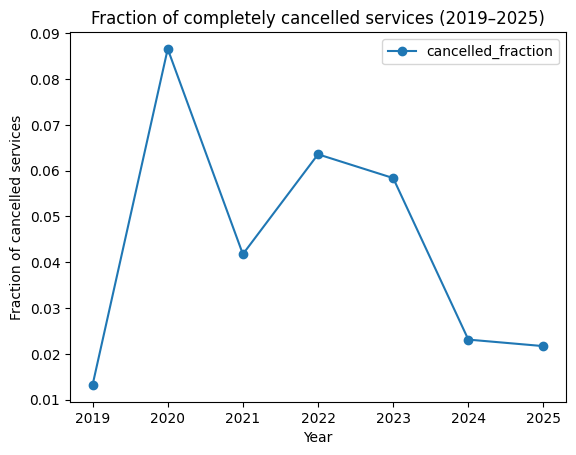

In [61]:
ax = yearly_cancellations.plot.line(
    x="year",
    y="cancelled_fraction",
    marker="o",
    title="Fraction of completely cancelled services (2019–2025)",
)
ax.set_xlabel("Year")
ax.set_ylabel("Fraction of cancelled services")
ax.set_xticks(yearly_cancellations["year"])
plt.show()

## Enrich service table

### Create station_connections

In [62]:
db.sql("""
CREATE TABLE IF NOT EXISTS station_connections AS
WITH ordered_stations AS (
    SELECT
        "Service:RDT-ID" AS service_id,
        UPPER("Stop:Station code") AS station_code,
        LEAD(UPPER("Stop:Station code")) OVER (
            PARTITION BY "Service:RDT-ID"
            ORDER BY "Stop:Departure time" NULLS LAST
        ) AS next_station_code
    FROM services
    WHERE "Stop:Station code" IS NOT NULL
),
service_pairs AS (
    SELECT DISTINCT
        service_id,
        station_code AS start_station_code,
        next_station_code AS end_station_code
    FROM ordered_stations
    WHERE next_station_code IS NOT NULL
      AND station_code <> next_station_code
)
SELECT
    p.service_id AS "Service:RDT-ID",
    p.start_station_code,
    p.end_station_code,
    d.distance
FROM service_pairs p
JOIN distances_long d
  ON UPPER(d.Station) = p.start_station_code
 AND UPPER(d.other_station) = p.end_station_code
""")

db.sql("DESCRIBE station_connections").show()
db.sql("SELECT * FROM station_connections LIMIT 5").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│    column_name     │ column_type │  null   │   key   │ default │  extra  │
│      varchar       │   varchar   │ varchar │ varchar │ varchar │ varchar │
├────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Service:RDT-ID     │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ start_station_code │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ end_station_code   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ distance           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
└────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │  int64   │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│       11032914 │ HKS    

### Largest distance between a pair of stations used by trains

In [63]:
db.sql("""
SELECT
    start_station_code,
    end_station_code,
    distance
FROM station_connections
ORDER BY distance DESC
LIMIT 1
""").show()

┌────────────────────┬──────────────────┬──────────┐
│ start_station_code │ end_station_code │ distance │
│      varchar       │     varchar      │  int64   │
├────────────────────┼──────────────────┼──────────┤
│ VS                 │ STV              │      421 │
└────────────────────┴──────────────────┴──────────┘



### Histogram of inter-station distances

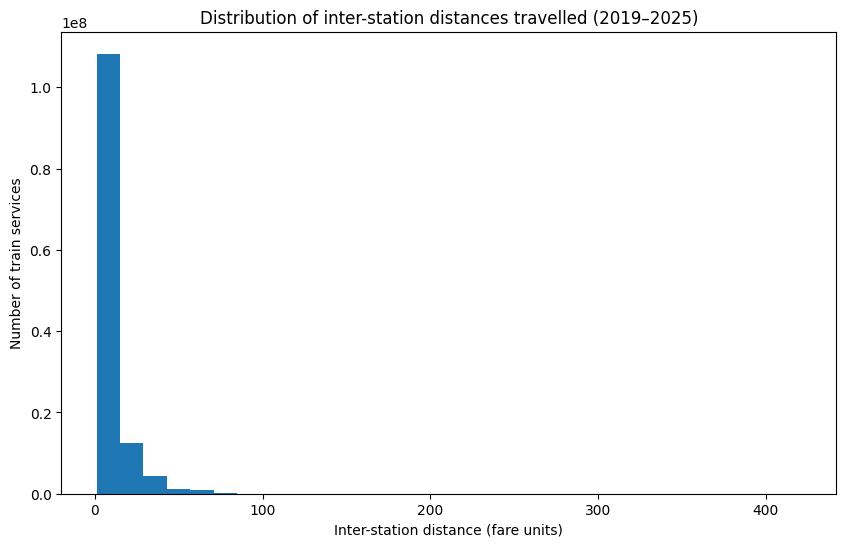

In [65]:
inter_station_distances = db.sql("""
SELECT distance
FROM station_connections
WHERE distance IS NOT NULL
""").df()

ax = inter_station_distances.plot.hist(
    y="distance",
    bins=30,
    figsize=(10, 6),
    title="Distribution of inter-station distances travelled (2019–2025)",
    legend=False,
)
ax.set_xlabel("Inter-station distance (fare units)")
ax.set_ylabel("Number of train services")
plt.show()